# Tema: "Mobile Legends" – Hero Game Fantasi MLBB
Nama : Ahmad Fauzi   
NIM    : 32602500053

## 1. Mini-Korpus Teks

### Latar Belakang Tema

*Mobile Legends Bang Bang* adalah game Multiplayer Online yang bertarung dalam satu arena untuk perangkat mobile yang dikembangkan oleh Moonton. Dalam satu pertandingan terdiri dari dua tim, dimana masing-masing tim beranggotakan lima pemain. Setiap pemain memilih satu hero dengan peran yang berbeda, sehingga komposisi tim sangat menentukan strategi permainan untuk mencapai kemenangan (Victory) atau kekalahan (Defeat).    
Korpus ini berisi lima deskripsi singkat hero dari game Mobile Legends: Bang Bang, mewakili lima role berbeda: Marksman (Layla), Tank (Tigreal), Mage (Eudora), Assassin (Saber), dan Fighter (Alucard).    
Tema ini dipilih karena antar-role punya kata yang beririsan (misalnya musuh, damage, jarak) sekaligus kata khas (misalnya garis depan untuk Tank dan Fighter), sehingga perbedaannya terlihat jelas pada matriks.

In [9]:
# Mini-korpus: 5 dokumen, masing-masing mendeskripsikan satu hero
korpus = [
    "Layla adalah hero Marksman yang menembak musuh dengan cepat dari jarak jauh dengan damage tinggi.",
    "Tigreal adalah hero Tank yang melindungi tim dan menahan musuh di garis depan dengan damage rendah.",
    "Eudora adalah hero Mage yang melepaskan petir dari jarak jauh dengan damage tinggi.",
    "Saber adalah hero Assassin yang menyerang musuh dari belakang dan membunuh musuh dengan damage tinggi.",
    "Alucard adalah hero Fighter yang menyerang musuh di garis depan bersama tim dan menahan serangan musuh.",
]

# Nama dokumen otomatis: D1, D2, D3, D4, D5
nama_dokumen = [f"D{i+1}" for i in range(len(korpus))]

# Tampilkan korpus
for n, teks in zip(nama_dokumen, korpus):
    print(f"{n}: {teks}")

D1: Layla adalah hero Marksman yang menembak musuh dengan cepat dari jarak jauh dengan damage tinggi.
D2: Tigreal adalah hero Tank yang melindungi tim dan menahan musuh di garis depan dengan damage rendah.
D3: Eudora adalah hero Mage yang melepaskan petir dari jarak jauh dengan damage tinggi.
D4: Saber adalah hero Assassin yang menyerang musuh dari belakang dan membunuh musuh dengan damage tinggi.
D5: Alucard adalah hero Fighter yang menyerang musuh di garis depan bersama tim dan menahan serangan musuh.


## 2. Pre-processing & Pembentukan Vocabulary

In [10]:
import re

# Daftar stopword sederhana (kata umum yang tidak membawa makna khusus)
stopwords = {"adalah", "yang", "dari", "dan", "di", "dengan", "bersama"}

def preprocess(teks):
    teks = teks.lower()                              # 1. case folding (huruf kecil semua)
    teks = re.sub(r"[^\w\s]", "", teks)              # 2. hapus tanda baca
    token = teks.split()                             # 3. tokenisasi (pecah per kata)
    return [t for t in token if t not in stopwords]  # 4. stopword removal

# Terapkan ke seluruh dokumen
korpus_bersih = [preprocess(d) for d in korpus]

# Cetak hasilnya
for n, tokens in zip(nama_dokumen, korpus_bersih):
    print(n, tokens)

D1 ['layla', 'hero', 'marksman', 'menembak', 'musuh', 'cepat', 'jarak', 'jauh', 'damage', 'tinggi']
D2 ['tigreal', 'hero', 'tank', 'melindungi', 'tim', 'menahan', 'musuh', 'garis', 'depan', 'damage', 'rendah']
D3 ['eudora', 'hero', 'mage', 'melepaskan', 'petir', 'jarak', 'jauh', 'damage', 'tinggi']
D4 ['saber', 'hero', 'assassin', 'menyerang', 'musuh', 'belakang', 'membunuh', 'musuh', 'damage', 'tinggi']
D5 ['alucard', 'hero', 'fighter', 'menyerang', 'musuh', 'garis', 'depan', 'tim', 'menahan', 'serangan', 'musuh']


In [11]:
# Vocabulary: 9 kata kunci unik yang mewakili seluruh dokumen
vocabulary = ["musuh", "damage", "tinggi", "jarak", "jauh", "cepat", "garis", "depan", "tim"]

print("Jumlah term:", len(vocabulary))
print(vocabulary)

Jumlah term: 9
['musuh', 'damage', 'tinggi', 'jarak', 'jauh', 'cepat', 'garis', 'depan', 'tim']


## 3. Konstruksi Matriks Representasi

In [12]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# Gabungkan token bersih menjadi string agar bisa dibaca CountVectorizer
korpus_str = [" ".join(t) for t in korpus_bersih]

# Matriks 2: Term Frequency (jumlah kemunculan tiap term)
cv = CountVectorizer(vocabulary=vocabulary)
tf_array = cv.fit_transform(korpus_str).toarray()
df_tf = pd.DataFrame(tf_array, index=nama_dokumen, columns=vocabulary)

# Matriks 1: Binary (1 jika term muncul minimal sekali, selain itu 0)
df_biner = (df_tf > 0).astype(int)

In [13]:
print ("=== Matriks 1: Model Binary (Boolean Vector) ===")
display(df_biner)

=== Matriks 1: Model Binary (Boolean Vector) ===


,musuh,damage,tinggi,jarak,jauh,cepat,garis,depan,tim
D1,1,1,1,1,1,1,0,0,0
D2,1,1,0,0,0,0,1,1,1
D3,0,1,1,1,1,0,0,0,0
D4,1,1,1,0,0,0,0,0,0
D5,1,0,0,0,0,0,1,1,1


In [14]:
print ("=== Matriks 2: Model Term Frequency (TF Vector) ===")
display(df_tf)

=== Matriks 2: Model Term Frequency (TF Vector) ===


,musuh,damage,tinggi,jarak,jauh,cepat,garis,depan,tim
D1,1,1,1,1,1,1,0,0,0
D2,1,1,0,0,0,0,1,1,1
D3,0,1,1,1,1,0,0,0,0
D4,2,1,1,0,0,0,0,0,0
D5,2,0,0,0,0,0,1,1,1


## 4. Visualisasi Heatmap & Styling 

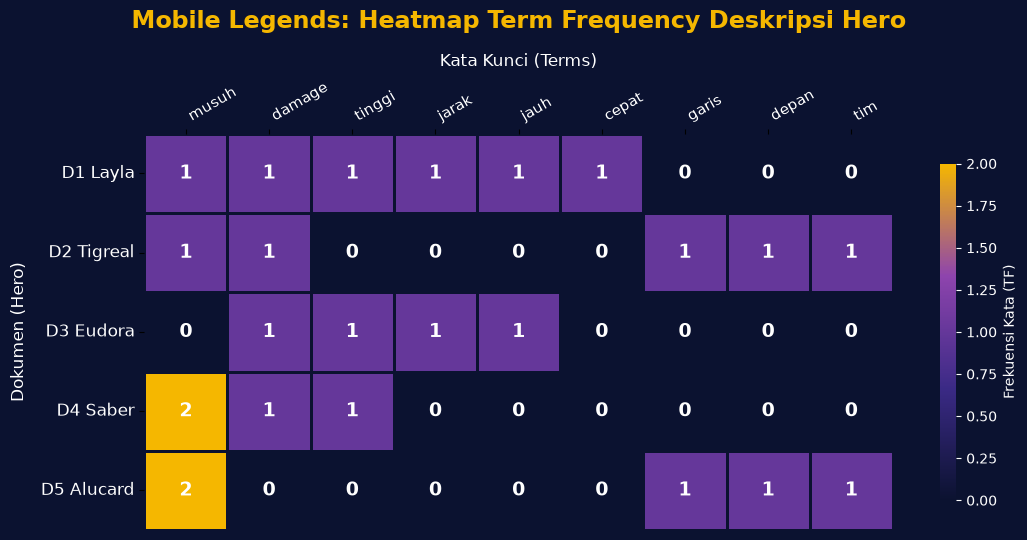

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Skema warna bertema Mobile Legends: biru gelap -> ungu -> emas
cmap_ml = LinearSegmentedColormap.from_list(
    "mlbb", ["#0b1230", "#3b2a86", "#8e44ad", "#f5b700"]
)

fig, ax = plt.subplots(figsize=(11, 5.5))
fig.patch.set_facecolor("#0b1230")
ax.set_facecolor("#0b1230")

sns.heatmap(
    df_tf,
    annot=True, fmt="d",
    cmap=cmap_ml,
    linewidths=2, linecolor="#0b1230",
    annot_kws={"size": 14, "weight": "bold", "color": "white"},
    cbar_kws={"label": "Frekuensi Kata (TF)", "shrink": 0.85},
    ax=ax,
)

ax.set_title("Mobile Legends: Heatmap Term Frequency Deskripsi Hero",
             fontsize=17, fontweight="bold", color="#f5b700", pad=18)
ax.set_xlabel("Kata Kunci (Terms)", fontsize=12, color="white", labelpad=10)
ax.set_ylabel("Dokumen (Hero)", fontsize=12, color="white", labelpad=10)
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="left", color="white", fontsize=11)
ax.set_yticklabels(
    ["D1 Layla", "D2 Tigreal", "D3 Eudora", "D4 Saber", "D5 Alucard"],
    rotation=0, color="white", fontsize=12)

# Warna label colorbar
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.label.set_color("white")
cbar.ax.tick_params(colors="white")

plt.tight_layout()
plt.show()

### Data pendukung analisis

In [16]:
# Jumlah kata unik per dokumen (variasi kata)
variasi = (df_tf > 0).sum(axis=1)
print("Jumlah kata unik per dokumen:")
print(variasi.to_string())

# Cosine similarity antar dokumen berdasarkan vektor TF
from sklearn.metrics.pairwise import cosine_similarity
sim = pd.DataFrame(cosine_similarity(df_tf),
                   index=nama_dokumen, columns=nama_dokumen).round(2)
print("\nCosine similarity antar dokumen (TF):")
display(sim)

Jumlah kata unik per dokumen:
D1    6
D2    5
D3    4
D4    3
D5    4

Cosine similarity antar dokumen (TF):


,D1,D2,D3,D4,D5
D1,1.00,0.37,0.82,0.67,0.31
D2,0.37,1.00,0.22,0.55,0.85
D3,0.82,0.22,1.00,0.41,0.00
D4,0.67,0.55,0.41,1.00,0.62
D5,0.31,0.85,0.00,0.62,1.00


## 5. Analisis Vektor Dokumen

**Variasi kata terbanyak:** Dokumen **D1 (Layla)** memiliki variasi kata terbanyak, yaitu 6 dari 9 term vocabulary muncul (musuh, damage, tinggi, jarak, jauh, cepat), sedangkan dokumen lain hanya 3–5 term.       
**Dua dokumen paling mirip:** **D2 (Tigreal) dan D5 (Alucard)**, karena keduanya sama-sama memuat term *musuh*, *garis*, *depan*, dan *tim*, sehingga pola warna pada heatmap di kolom-kolom tersebut hampir sama. Seluruh term milik D5 juga ada di D2, dan kemiripan ini didukung nilai cosine similarity 0,85 yang tertinggi di antara semua pasangan.  
Hal ini masuk akal karena Tank dan Fighter sama-sama bermain di garis depan bersama tim, berbeda dengan D1 dan D3 yang berfokus pada serangan jarak jauh.